# Merge `Decisao` Classes — 10 → 8, via a Similarity Measure

`22_Merge_Decisao_Classes.ipynb` picked its merge (fold `CONFIRMAÇÃO` and `CONFIRMADA A DECISÃO RECORRIDA` into `CONFIRMADA`) by reading.

## Section 1 — Setup & Load

Same source dataset as `22_Merge_Decisao_Classes.ipynb`: `preprocessed_grupo3.csv` (10-class) and its label map.

In [1]:
import json
import sys
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.preprocessing import LabelEncoder
from transformers import AutoModel, AutoTokenizer, logging as hf_logging

hf_logging.set_verbosity_error()
sys.path.insert(0, str(Path('../..').resolve()))
from src.config import DATA_DIR, OUTPUTS_DIR

df = pd.read_csv(DATA_DIR / 'preprocessed_grupo3.csv')
with open(DATA_DIR / 'label2id_grupo3.json', encoding='utf-8') as f:
    label_map_10 = json.load(f)
labels = label_map_10['labels']

SIMILARITY_MODEL_ID = 'stjiris/bert-large-portuguese-cased-legal-mlm-nli-sts-v1'
sts_tokenizer = AutoTokenizer.from_pretrained(SIMILARITY_MODEL_ID)
sts_model = AutoModel.from_pretrained(SIMILARITY_MODEL_ID)
sts_model.eval()

print(f'Loaded {len(df):,} rows, {df["Decisao"].nunique()} classes')
print(f'Similarity model: {SIMILARITY_MODEL_ID}')

<project>/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 22973.96it/s]

Loaded 10,153 rows, 10 classes
Similarity model: stjiris/bert-large-portuguese-cased-legal-mlm-nli-sts-v1


## Section 2 — Embed the 10 Labels & Compute Pairwise Similarity

Mean-pools the STS model's last hidden state over each label string (same pooling convention as `src.capture.pool_mean` / `src.knn_probe`).

In [2]:
@torch.no_grad()
def embed_labels(texts: list[str]) -> torch.Tensor:
    encoding = sts_tokenizer(texts, padding=True, truncation=True, return_tensors='pt')
    outputs = sts_model(**encoding)
    mask = encoding['attention_mask'].unsqueeze(-1).float()
    pooled = (outputs.last_hidden_state * mask).sum(1) / mask.sum(1)
    return F.normalize(pooled, dim=1)

label_embeddings = embed_labels(labels)
similarity = (label_embeddings @ label_embeddings.T).numpy()

sim_df = pd.DataFrame(similarity, index=labels, columns=labels)
sim_df.round(2)

,APELAÇÃO IMPROCEDENTE,CONFIRMADA,CONFIRMADA A DECISÃO RECORRIDA,CONFIRMAÇÃO,IMPROCEDENTE,NÃO PROVIDO,PARCIALMENTE PROCEDENTE,PROCEDENTE,REVOGADA,REVOGADA EM PARTE
APELAÇÃO IMPROCEDENTE,1.00,0.20,0.49,0.17,0.61,0.54,0.59,0.61,0.30,0.31
CONFIRMADA,0.20,1.00,0.43,0.72,0.29,0.25,0.22,0.33,0.25,0.19
CONFIRMADA A DECISÃO RECORRIDA,0.49,0.43,1.00,0.41,0.30,0.54,0.50,0.57,0.45,0.50
CONFIRMAÇÃO,0.17,0.72,0.41,1.00,0.18,0.19,0.19,0.22,0.17,0.14
IMPROCEDENTE,0.61,0.29,0.30,0.18,1.00,0.43,0.41,0.54,0.29,0.26
NÃO PROVIDO,0.54,0.25,0.54,0.19,0.43,1.00,0.58,0.71,0.39,0.43
PARCIALMENTE PROCEDENTE,0.59,0.22,0.50,0.19,0.41,0.58,1.00,0.76,0.35,0.45
PROCEDENTE,0.61,0.33,0.57,0.22,0.54,0.71,0.76,1.00,0.41,0.42
REVOGADA,0.30,0.25,0.45,0.17,0.29,0.39,0.35,0.41,1.00,0.85
REVOGADA EM PARTE,0.31,0.19,0.50,0.14,0.26,0.43,0.45,0.42,0.85,1.00


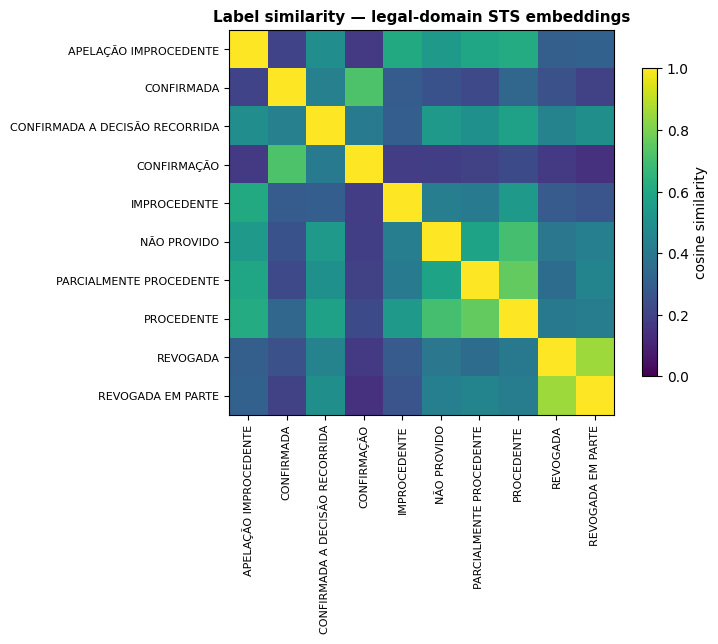

In [3]:
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(similarity, cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=90, fontsize=8)
ax.set_yticklabels(labels, fontsize=8)
ax.set_title('Label similarity — legal-domain STS embeddings', fontsize=11, fontweight='bold')
fig.colorbar(im, ax=ax, shrink=0.8, label='cosine similarity')
plt.tight_layout()
plt.savefig('../../reports/figures/label_similarity_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## Section 3 — Hierarchical Clustering

`1 - similarity` (symmetrized) is the distance matrix fed to average-linkage clustering.

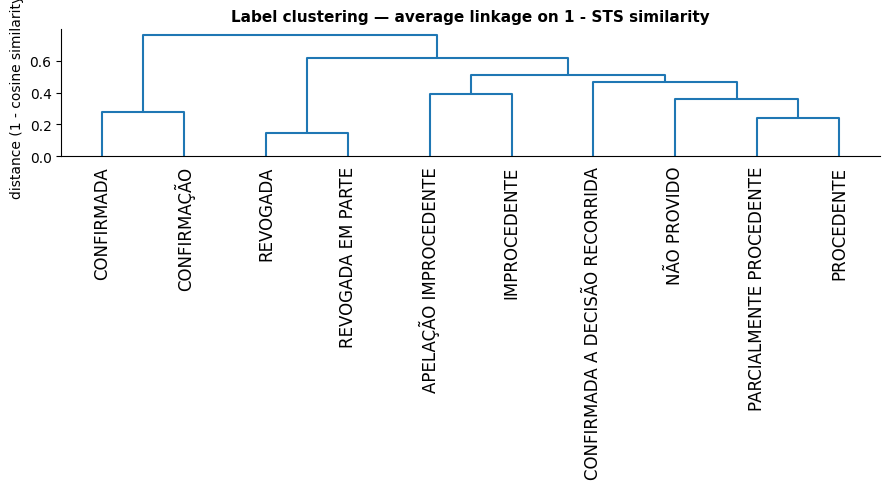

Merges, in order of increasing distance (leaf/cluster ids from scipy, cluster ids >= 10):
  step 0: merge 8 + 9  (distance=0.146, resulting size=2)
  step 1: merge 6 + 7  (distance=0.241, resulting size=2)
  step 2: merge 1 + 3  (distance=0.278, resulting size=2)
  step 3: merge 5 + 11  (distance=0.357, resulting size=3)
  step 4: merge 0 + 4  (distance=0.393, resulting size=2)
  step 5: merge 2 + 13  (distance=0.464, resulting size=4)
  step 6: merge 14 + 15  (distance=0.512, resulting size=6)
  step 7: merge 10 + 16  (distance=0.619, resulting size=8)
  step 8: merge 12 + 17  (distance=0.759, resulting size=10)


In [4]:
distance = 1 - similarity
np.fill_diagonal(distance, 0)
distance = (distance + distance.T) / 2
condensed = squareform(distance, checks=False)

Z = linkage(condensed, method='average')

fig, ax = plt.subplots(figsize=(9, 5))
dendrogram(Z, labels=labels, leaf_rotation=90, ax=ax, color_threshold=0)
ax.set_title('Label clustering — average linkage on 1 - STS similarity', fontsize=11, fontweight='bold')
ax.set_ylabel('distance (1 - cosine similarity)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('../../reports/figures/label_dendrogram.png', dpi=150, bbox_inches='tight')
plt.show()

print('Merges, in order of increasing distance (leaf/cluster ids from scipy, cluster ids >= 10):')
for step, (a, b, dist, size) in enumerate(Z):
    print(f'  step {step}: merge {int(a)} + {int(b)}  (distance={dist:.3f}, resulting size={int(size)})')

In [5]:
N_TARGET_CLASSES = 8
cluster_ids = fcluster(Z, t=N_TARGET_CLASSES, criterion='maxclust')
n_clusters_found = len(set(cluster_ids))
assert n_clusters_found == N_TARGET_CLASSES, (
    f'Expected {N_TARGET_CLASSES} clusters, got {n_clusters_found} -- tree has ties at this cut height'
)

clusters = {}
for label, cluster_id in zip(labels, cluster_ids):
    clusters.setdefault(int(cluster_id), []).append(label)

for cluster_id, members in sorted(clusters.items()):
    print(f'cluster {cluster_id}: {members}')

cluster 1: ['CONFIRMADA']
cluster 2: ['CONFIRMAÇÃO']
cluster 3: ['REVOGADA', 'REVOGADA EM PARTE']
cluster 4: ['APELAÇÃO IMPROCEDENTE']
cluster 5: ['IMPROCEDENTE']
cluster 6: ['PARCIALMENTE PROCEDENTE', 'PROCEDENTE']
cluster 7: ['NÃO PROVIDO']
cluster 8: ['CONFIRMADA A DECISÃO RECORRIDA']


## Section 4 — Build the Merge Map

Each cluster's canonical name is its most frequent original label (by row count).

In [6]:
class_counts = df['Decisao'].value_counts()

CLASS_MERGE_MAP = {}
for cluster_id, members in clusters.items():
    canonical = max(members, key=lambda label: class_counts[label])
    for member in members:
        CLASS_MERGE_MAP[member] = canonical

assert set(CLASS_MERGE_MAP) == set(labels)
n_target_classes = len(set(CLASS_MERGE_MAP.values()))
print(f'{len(CLASS_MERGE_MAP)} original labels -> {n_target_classes} merged classes')
pd.DataFrame(sorted(CLASS_MERGE_MAP.items()), columns=['original_label', 'merged_label'])

10 original labels -> 8 merged classes


,original_label,merged_label
0,APELAÇÃO IMPROCEDENTE,APELAÇÃO IMPROCEDENTE
1,CONFIRMADA,CONFIRMADA
2,CONFIRMADA A DECISÃO RECORRIDA,CONFIRMADA A DECISÃO RECORRIDA
3,CONFIRMAÇÃO,CONFIRMAÇÃO
4,IMPROCEDENTE,IMPROCEDENTE
5,NÃO PROVIDO,NÃO PROVIDO
6,PARCIALMENTE PROCEDENTE,PROCEDENTE
7,PROCEDENTE,PROCEDENTE
8,REVOGADA,REVOGADA
9,REVOGADA EM PARTE,REVOGADA


## Section 5 — Apply the Merge

Same convention as `22_Merge_Decisao_Classes.ipynb`: `Decisao_original` keeps the pre-merge label.

In [7]:
df['Decisao_original'] = df['Decisao']
df['Decisao'] = df['Decisao_original'].map(CLASS_MERGE_MAP)

assert df['Decisao'].notna().all(), 'Some rows failed to map -- CLASS_MERGE_MAP is incomplete'

before = df['Decisao_original'].value_counts()
after = df['Decisao'].value_counts()

print(f'Before: {len(before)} classes, {before.sum():,} rows')
print(f'After : {len(after)} classes, {after.sum():,} rows')
assert before.sum() == after.sum(), 'Merge changed the total row count'
after

Before: 10 classes, 10,153 rows
After : 8 classes, 10,153 rows


Decisao
CONFIRMADA                        3405
IMPROCEDENTE                      1851
REVOGADA                          1799
PROCEDENTE                        1126
NÃO PROVIDO                        579
APELAÇÃO IMPROCEDENTE              540
CONFIRMAÇÃO                        479
CONFIRMADA A DECISÃO RECORRIDA     374
Name: count, dtype: int64

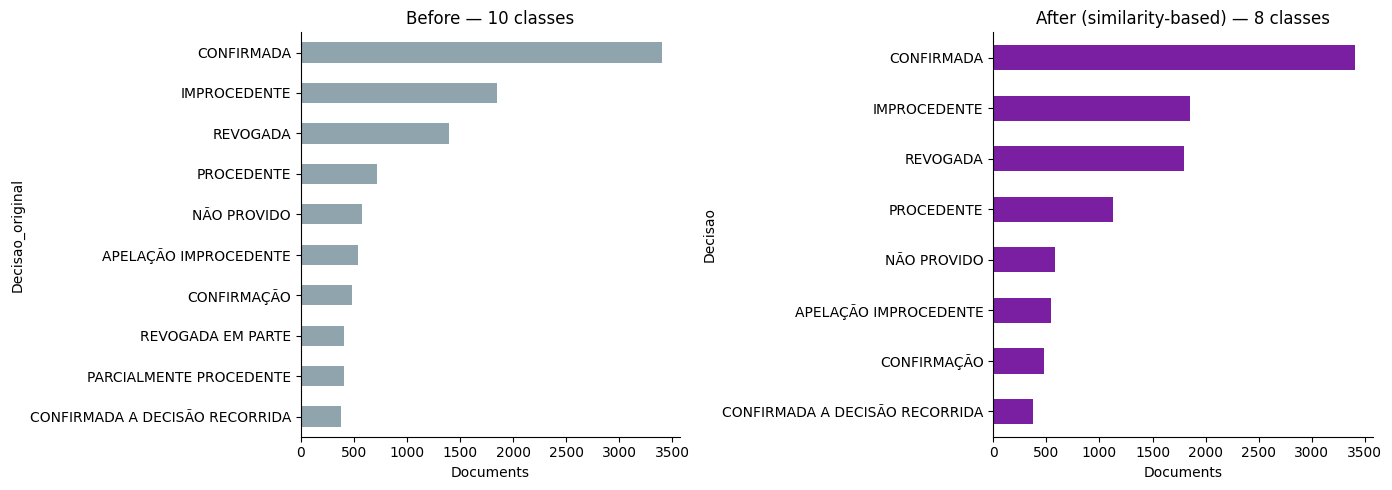

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

before.sort_values().plot.barh(ax=axes[0], color='#90A4AE')
axes[0].set_title(f'Before — {len(before)} classes')
axes[0].set_xlabel('Documents')

after.sort_values().plot.barh(ax=axes[1], color='#7B1FA2')
axes[1].set_title(f'After (similarity-based) — {len(after)} classes')
axes[1].set_xlabel('Documents')

for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('../../reports/figures/class_distribution_8class_similarity.png', dpi=150, bbox_inches='tight')
plt.show()

## Section 6 — Sanity Checks

Same two checks as the manual-merge notebook: `split` is untouched, and every merged class has at least one row in each of train/val/test.

In [9]:
assert set(df['split'].unique()) <= {'train', 'val', 'test'}

split_counts = df.groupby(['split', 'Decisao']).size().unstack('Decisao').fillna(0).astype(int)
split_counts = split_counts.reindex(['train', 'val', 'test'])
print('Rows per class, per split:')
print(split_counts.T.to_string())

train_classes = set(df.loc[df['split'] == 'train', 'Decisao'].unique())
for other_split in ['val', 'test']:
    split_classes = set(df.loc[df['split'] == other_split, 'Decisao'].unique())
    orphans = train_classes - split_classes
    print(f'\nTrain classes absent from {other_split}: {len(orphans)}')
    assert not orphans, f'{orphans} has zero rows in {other_split} -- cannot be evaluated'

Rows per class, per split:
split                           train  val  test
Decisao                                         
APELAÇÃO IMPROCEDENTE             405   54    81
CONFIRMADA                       2552  342   511
CONFIRMADA A DECISÃO RECORRIDA    281   38    55
CONFIRMAÇÃO                       359   48    72
IMPROCEDENTE                     1388  185   278
NÃO PROVIDO                       434   58    87
PROCEDENTE                        845  112   169
REVOGADA                         1350  179   270

Train classes absent from val: 0

Train classes absent from test: 0


## Section 7 — Diagnostic: Collapsing the Existing Confusion Matrix

Same no-retrain estimate as the manual-merge notebook: collapse LegalBERT's 10-class test confusion matrix along this notebook's.

In [10]:
with open(OUTPUTS_DIR / 'legalbert' / 'finetune' / 'metrics.json', encoding='utf-8') as f:
    legalbert_metrics = json.load(f)

cm_labels_10 = legalbert_metrics['confusion_matrix_labels']
cm_10 = np.array(legalbert_metrics['confusion_matrix'])
assert cm_labels_10 == labels, 'Confusion matrix label order has drifted from label2id_grupo3.json'

merged_labels = sorted(set(CLASS_MERGE_MAP.values()))
merged_index = {label: i for i, label in enumerate(merged_labels)}

cm_8 = np.zeros((len(merged_labels), len(merged_labels)), dtype=int)
for i, true_label in enumerate(cm_labels_10):
    for j, pred_label in enumerate(cm_labels_10):
        ti = merged_index[CLASS_MERGE_MAP[true_label]]
        pj = merged_index[CLASS_MERGE_MAP[pred_label]]
        cm_8[ti, pj] += cm_10[i, j]

accuracy_10 = np.trace(cm_10) / cm_10.sum()
accuracy_8 = np.trace(cm_8) / cm_8.sum()
print(f'10-class test accuracy (actual)                          : {accuracy_10:.4f}')
print(f'8-class test accuracy (similarity-based merge, no retrain): {accuracy_8:.4f}')
print(f'Delta from collapsing alone                                : {accuracy_8 - accuracy_10:+.4f}')

pd.DataFrame(cm_8, index=merged_labels, columns=merged_labels)

10-class test accuracy (actual)                          : 0.4183
8-class test accuracy (similarity-based merge, no retrain): 0.4570
Delta from collapsing alone                                : +0.0387


,APELAÇÃO IMPROCEDENTE,CONFIRMADA,CONFIRMADA A DECISÃO RECORRIDA,CONFIRMAÇÃO,IMPROCEDENTE,NÃO PROVIDO,PROCEDENTE,REVOGADA
APELAÇÃO IMPROCEDENTE,25,17,5,3,3,2,11,15
CONFIRMADA,28,231,14,43,8,14,16,157
CONFIRMADA A DECISÃO RECORRIDA,2,2,36,1,4,1,5,4
CONFIRMAÇÃO,3,26,0,22,1,1,0,19
IMPROCEDENTE,17,16,4,4,108,15,93,21
NÃO PROVIDO,2,2,0,2,4,65,9,3
PROCEDENTE,12,11,1,1,34,11,84,15
REVOGADA,16,81,8,19,4,4,13,125


## Section 8 — Export

Written under distinct filenames from `22_Merge_Decisao_Classes.ipynb`'s manual merge.

In [11]:
EXPORT_COLS = [
    'ImportJurisprudenciaId', 'source', 'Sumario_raw', 'Sumario', 'Decisao', 'Decisao_original',
    'TipoDecisao', 'group_id', 'split', 'cv_fold',
]

export_path = DATA_DIR / 'preprocessed_grupo3_8class_similarity.csv'
df[EXPORT_COLS].to_csv(export_path, index=False, encoding='utf-8')
print(f'Exported: {export_path}  ({len(df):,} rows)')

le = LabelEncoder().fit(df['Decisao'])
labels_8 = list(le.classes_)
label2id_8 = {cls: int(i) for i, cls in enumerate(le.classes_)}
id2label_8 = {int(i): cls for i, cls in enumerate(le.classes_)}

label_path = DATA_DIR / 'label2id_grupo3_8class_similarity.json'
with open(label_path, 'w', encoding='utf-8') as f:
    json.dump(
        {'labels': labels_8, 'label2id': label2id_8, 'id2label': id2label_8},
        f, ensure_ascii=False, indent=2,
    )
print(f'Label mapping saved -> {label_path}  ({len(label2id_8)} classes)')

Exported: <project>/data/2_processed/preprocessed_grupo3_8class_similarity.csv  (10,153 rows)


Label mapping saved -> <project>/data/2_processed/label2id_grupo3_8class_similarity.json  (8 classes)
